# Reproducing Figures 1–3: cuticular conductance ($g_{cw}$) and instrumental noise in low-$g_{sw}$ photosynthetic parameter estimation

[Accurate photosynthetic parameter estimation at low stomatal conductance: effects of cuticular conductance and instrumental noise](https://doi.org/10.1007/s11120-024-01092-8), *Photosynthesis Research* 160(2-3):111-124 (2024), CC BY 4.0, PMCID PMC11108943.

**Purpose.** The paper shows that at low leaf conductance, uncorrected
cuticular conductance ($g_{cw}$) and LI-6800 instrumental noise bias the
estimated internal CO₂ concentration ($C_i$) from A/Ci curve fitting. The
authors released self-contained R scripts (supplements S2, S3) that sweep
total leaf conductance $g_{tw}$ from 0.01 to 1 mol m⁻² s⁻¹ through the
`plantecophys::Photosyn()` Farquhar solver and plot the proportional $C_i$
misestimation (paper Figures 1–3).

**Exact scope of this notebook (partial demonstration).** We re-run the
authors' own pinned simulation scripts S3 (→ paper Figures 1 & 2) and S2
(→ paper Figure 3) with three documented repairs, and display their saved
figures plus small result tables. **Not executed here:** the S1 curve-fitting
branch (it reads the authors' private Dropbox CSVs), the Statistix 8.1
statistics (commercial, no script exists), and all measured data (S4/S5).

**Execution status.** CPU-only Colab runtime, executed end-to-end
(R via `Rscript`). No GPU code path exists in this reproduction.

/ **日本語**: このノートブックは、上記論文の補足 R スクリプト S2・S3
(論文 Figures 1–3 に対応するシミュレーション) をそのまま実行し、結果の図と
小さな表を表示します。CPU ランタイムのみを使用します。S1(著者私有の
Dropbox CSV が必要な曲線フィット)と Statistix による統計検定は対象外です。

> **AI-assisted note (EN/JP).** The author R scripts are used verbatim from the
> publisher (SHA-256 verified) except for four documented repairs (output
> directory, an undefined variable order, one undefined function defined
> from the authors' own formula, and a patchwork/ggplot2 4.x compatibility
> replacement). The authors did not provide this Colab
> wrapper; untested behavior is not guaranteed.
> / **日本語**: 著者の R スクリプトは発行元から取得したものを SHA-256 検証の上
> そのまま使用します。4 箇所の修正(出力先、変数定義順、未定義関数の定義、patchwork 互換)のみ
> 行っており、この Colab ラッパー自体は AI が作成したものです。

## Runtime selection and how to run

**Runtime: CPU only.** The method is a ~1,000-point parameter sweep through
the `plantecophys` Farquhar solver plus `ggplot2` rendering — pure CPU
numerics with < 1 GB memory. Select **Runtime → Change runtime type → CPU
(the free default)**. There is no GPU code path; a T4 would not change the
science. Typical end-to-end time: ~10–25 min (R + package install dominates);
downloads < 400 MB. / **日本語**: ランタイムは CPU のみで構いません。
所要時間の目安は全体で 10–25 分(主に R とパッケージのインストール)、
ダウンロードは 400 MB 未満です。GPU は不要です。

Run **Runtime → Run all**. Every download and computation happens inside this
Colab VM under `/content/`; nothing is read from Drive or the host.

## 1. Environment report

This cell prints the VM platform, Ubuntu codename (used later to pick matching
precompiled R package binaries), CPU count, memory, and whether R is already
present. / **日本語**: VM のプラットフォーム・Ubuntu コード名・CPU 数・メモリ、
および R の有無を確認します。

In [ ]:
import platform, subprocess, os

print("Python:", platform.python_version())
print("Platform:", platform.platform())
codename = ""
for line in open("/etc/os-release"):
    if line.startswith("VERSION_CODENAME="):
        codename = line.strip().split("=", 1)[1]
print("Ubuntu codename:", codename or "unknown")
print("CPUs:", os.cpu_count())
meminfo = {k: v for k, v in (l.split(":") for l in open("/proc/meminfo") if ":" in l)}
print("MemTotal:", meminfo.get("MemTotal", ("unknown",)).strip())
whoami = subprocess.run(["whoami"], capture_output=True, text=True).stdout.strip()
print("User:", whoami, "(apt-get requires root; the standard Colab VM runs as root)")
r_which = subprocess.run(["bash", "-lc", "command -v Rscript || true"],
                         capture_output=True, text=True).stdout.strip()
print("Rscript:", r_which or "not installed yet (installed below)")
assert whoami == "root", 'This notebook requires a root Colab VM for apt-get installation.'

Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Ubuntu codename: noble
CPUs: 2
MemTotal: 13286932 kB
User: root (apt-get requires root; the standard Colab VM runs as root)
Rscript: /usr/bin/Rscript


## 2. Install R

`apt-get` installs `r-base` (R interpreter + base packages) and
`r-base-dev` (compilers and headers, needed only if a package must be built
from source). This takes a few minutes and ~150 MB. / **日本語**:
`apt-get` で R 本体と開発ツールをインストールします(数分、約 150 MB)。

In [ ]:
import subprocess, time

t0 = time.time()

def sh(cmd, timeout=2400):
    print("$", " ".join(cmd), flush=True)
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="", flush=True)
    rc = proc.wait(timeout=timeout)
    if rc != 0:
        raise RuntimeError(f"command failed with exit code {rc}")

sh(["apt-get", "update", "-qq"])
sh(["apt-get", "install", "-y", "-qq",
    "r-base", "r-base-dev",
    "libcurl4-openssl-dev", "libssl-dev", "libxml2-dev",
    "libfontconfig1-dev", "libfreetype6-dev", "libpng-dev"])
print(f"apt install finished in {time.time() - t0:.0f}s", flush=True)
sh(["Rscript", "-e", "cat(R.version.string); cat(\"\\n\")"])

$ apt-get update -qq


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


$ apt-get install -y -qq r-base r-base-dev libcurl4-openssl-dev libssl-dev libxml2-dev libfontconfig1-dev libfreetype6-dev libpng-dev


Selecting previously unselected package libfontconfig1-dev:amd64.


(Reading database ... 


...

Unpacking libfontconfig1-dev:amd64 (2.15.0-1.1ubuntu2) ...


Setting up libfontconfig1-dev:amd64 (2.15.0-1.1ubuntu2) ...


apt install finished in 12s


$ Rscript -e cat(R.version.string); cat("\n")


R version 4.6.1 (2026-06-24)


## 3. Install the R packages used by the author scripts

The scripts need `plantecophys` (the Duursma Farquhar solver used in the
paper), `dplyr` and `ggplot2` (from tidyverse), and `patchwork` (figure
composition). We try precompiled Ubuntu binaries from Posit Package Manager
pinned to the paper's publication date (2024-05-03) for speed and
reproducibility; if binaries are unavailable for this R/distro combination we
fall back to a current snapshot, then to source builds from CRAN.
/ **日本語**: 著者スクリプトが必要とする 4 パッケージを導入します。まず
論文公開日(2024-05-03)時点のバイナリを試し、不可なら最新バイナリ、
さらに不可なら CRAN からソースビルドします。

In [ ]:
from pathlib import Path
import subprocess, time

install_r = r'''
codename <- system("lsb_release -cs", intern = TRUE)
pkgs <- c("dplyr", "ggplot2", "patchwork", "plantecophys")
have <- function(p) requireNamespace(p, quietly = TRUE)
attempt <- function(repos, tag) {
  missing <- pkgs[!vapply(pkgs, have, logical(1))]
  if (length(missing) == 0) return(TRUE)
  options(repos = c(CRAN = repos), timeout = 600)
  cat("installing:", paste(missing, collapse = ", "), sprintf("(%s)\n", tag))
  try(install.packages(missing, Ncpus = max(1, parallel::detectCores())),
      silent = TRUE)
  all(vapply(pkgs, have, logical(1)))
}
snap <- sprintf("https://packagemanager.posit.co/cran/__linux__/%s/2024-05-03", codename)
latest <- sprintf("https://packagemanager.posit.co/cran/__linux__/%s/latest", codename)
ok <- attempt(snap, "PPM snapshot 2024-05-03 (paper date)") ||
      attempt(latest, "PPM latest snapshot") ||
      attempt("https://cloud.r-project.org", "CRAN source")
stopifnot("R package installation failed" = ok)
if (packageVersion("patchwork") < "1.3.1") {
  cat("upgrading patchwork (>=1.3.1 needed for ggplot2 4.x guide collection)
")
  install.packages("patchwork", repos = "https://cloud.r-project.org")
}
stopifnot(packageVersion("patchwork") >= "1.3.1")
cat(R.version.string, "\n")
for (p in pkgs) cat(sprintf("  %-14s %s\n", p, as.character(packageVersion(p))))
'''
Path("/content/install_pkgs.R").write_text(install_r)
t0 = time.time()
proc = subprocess.Popen(["Rscript", "/content/install_pkgs.R"],
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                        text=True, bufsize=1)
for line in proc.stdout:
    print(line, end="", flush=True)
rc = proc.wait(timeout=2400)
if rc != 0:
    raise RuntimeError(f"R package install failed with exit code {rc}")
print(f"package install finished in {time.time() - t0:.0f}s", flush=True)

installing: patchwork, plantecophys (PPM snapshot 2024-05-03 (paper date))


Installing packages into ‘/usr/local/lib/R/site-library’


(as ‘lib’ is unspecified)


trying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2024-05-03/src/contrib/patchwork_1.2.0.tar.gz'


trying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2024-05-03/src/contrib/plantecophys_1.4-6.tar.gz'


...

  dplyr          1.2.1


  ggplot2        4.0.3


  patchwork      1.3.2


  plantecophys   1.4.6


package install finished in 25s


## 4. Download the authors' pinned R scripts (SHA-256 verified)

The two simulation scripts are fetched from the publisher's official
static-content host for DOI 10.1007/s11120-024-01092-8 (these are code files,
not data). Expected sizes and SHA-256 digests were computed on the DGX host
when this notebook was authored; the cell rejects any other bytes.
/ **日本語**: 著者の R スクリプト S2・S3 を発行元サーバーから取得し、
サイズと SHA-256 を検証します。一致しない場合は中断します。

In [ ]:
SPRINGER_BASE = ("https://static-content.springer.com/esm/"
                 "art%3A10.1007%2Fs11120-024-01092-8/MediaObjects")

import urllib.request, hashlib

SCRIPTS = {
    "S2_11120_2024_1092_MOESM2_ESM.r": {
        "url": SPRINGER_BASE + "/11120_2024_1092_MOESM2_ESM.r",
        "size": 12544,
        "sha256": "b62ddab9ce13fbc70566eb31128c6ab3b1fb5ccbe43c087c10f0a2de8c5be14a"},
    "S3_11120_2024_1092_MOESM3_ESM.r": {
        "url": SPRINGER_BASE + "/11120_2024_1092_MOESM3_ESM.r",
        "size": 9249,
        "sha256": "f4d4a97e108c17e1b7b170b5fa4e2a81538765e5eb2bffb554dd644c867b02b1"},
}

Path("/content/author_scripts").mkdir(exist_ok=True)
for name, meta in SCRIPTS.items():
    dest = Path("/content/author_scripts") / name
    with urllib.request.urlopen(meta["url"], timeout=120) as resp:
        data = resp.read()
    digest = hashlib.sha256(data).hexdigest()
    print(f"{name}: {len(data)} B  sha256={digest[:16]}...  status OK")
    assert len(data) == meta["size"], f"unexpected size for {name}"
    assert digest == meta["sha256"], f"SHA-256 mismatch for {name}"
    dest.write_bytes(data)
print("All author scripts verified against pinned digests.")

S2_11120_2024_1092_MOESM2_ESM.r: 12544 B  sha256=b62ddab9ce13fbc7...  status OK


S3_11120_2024_1092_MOESM3_ESM.r: 9249 B  sha256=f4d4a97e108c17e1...  status OK
All author scripts verified against pinned digests.


## 5. Apply the three documented repairs to the author scripts

The scripts were written on the author's laptop and need four minimal,
documented edits to run headless in Colab (no scientific change):

1. **Output directory**: both scripts call `setwd(...)` to the author's private
   Dropbox folder → redirect to `/content/phenopaper_out`.
2. **S3 variable order**: `magy/papy/pepy/city` (figure error-bar y-positions)
   are used in Figure-2 panel `a` but only defined later in the file → the
   four identical assignments are inserted before first use.
3. **S2 undefined function**: the `test_df` mutation calls `gsw_cor(gsw, gcw)`,
   which is never defined → defined here using exactly the authors' own
   `duursma_gsw()` formula (`gtc=(gsw-gcw)/1.6+gcw/20; gtc*1.6`).
4. **patchwork/ggplot2 4.x incompatibility**: both scripts end with
   `... & theme(legend.position = 'top')`, which errors on the current stack
   (ggplot2 4.0.3 + patchwork 1.2.0, verified in a diagnostic probe) →
   replaced with the equivalent `+ plot_annotation(theme = theme(...))`.

Each replacement asserts its exact source pattern, and a CSV export line is
appended so a small results table can be shown (export only, no computation
change). / **日本語**: 著者スクリプトに 4 種類の最小限の修正(出力先変更、
S3 の変数定義順の移動、S2 の未定義関数 `gsw_cor` を著者自身の
`duursma_gsw()` 式で定義、patchwork と ggplot2 4.x の非互換の解消)を
加えます。科学的な計算は一切変更していません。

In [ ]:
from pathlib import Path

AUTHOR_DROPBOX = ('setwd("/Users/civince/Dropbox (UFL)/Writing/RACiR/RACiR '
                  'Manuscript/Major update/Photosynthesis Research")')
OUTDIR_R = 'setwd("/content/phenopaper_out")'

def repair(src, replacements, append, name):
    for old, new, label in replacements:
        assert old in src, f"{name}: repair pattern not found: {label}"
        src = src.replace(old, new)
    return src + append

s3 = Path("/content/author_scripts/S3_11120_2024_1092_MOESM3_ESM.r").read_text()
s3 = repair(
    s3,
    [(AUTHOR_DROPBOX, OUTDIR_R, "setwd -> /content/phenopaper_out"),
     ("offsety1=.04",
      "offsety1=.04\nmagy=0.1\npapy=0.3\npepy=0.4\ncity=0.2",
      "insert magy/papy/pepy/city before first use in panel a"),
     ("& theme(legend.position = 'top')",
      "+ plot_annotation(theme = theme(legend.position = 'top'))",
      "patchwork &-theme incompatibility with ggplot2 4.x (verified repair)")],
    '\nwrite.csv(df, file.path(getwd(), "S3_curve_results.csv"), row.names = FALSE)\n',
    "S3")
Path("/content/S3_repaired.r").write_text(s3)

s2 = Path("/content/author_scripts/S2_11120_2024_1092_MOESM2_ESM.r").read_text()
s2 = repair(
    s2,
    [(AUTHOR_DROPBOX, OUTDIR_R, "setwd -> /content/phenopaper_out"),
     ("test_df <- df %>%\n  group_by(Ca)%>%",
      "# AI repair: gsw_cor() is called below but never defined in the script;\n"
      "# defined here with the authors' own duursma_gsw() formula (S2 lines 63-69).\n"
      "gsw_cor <- function(gsw, gcw) {\n"
      "  gtc <- (gsw - gcw) / 1.6 + gcw / 20\n"
      "  gtc * 1.6\n"
      "}\n"
      "test_df <- df %>%\n  group_by(Ca)%>%",
      "define gsw_cor per author duursma_gsw formula"),
     ("& theme(legend.position = 'top')",
      "+ plot_annotation(theme = theme(legend.position = 'top'))",
      "patchwork &-theme incompatibility with ggplot2 4.x (verified repair)")],
    '\nwrite.csv(test_df, file.path(getwd(), "S2_curve_results.csv"), row.names = FALSE)\n',
    "S2")
Path("/content/S2_repaired.r").write_text(s2)
print("Wrote /content/S3_repaired.r and /content/S2_repaired.r")
print("Applied: 4 documented repairs + 2 CSV export lines")

Wrote /content/S3_repaired.r and /content/S2_repaired.r
Applied: 4 documented repairs + 2 CSV export lines


## 6. Preview the simulation inputs

There is no external dataset: the "input" is the $g_{tw}$ sweep and the
fixed physiological parameters taken verbatim from the author scripts — the
sweep `seq(0.01, 1, by = 0.001)`, ambient CO₂ levels $C_a \in
\{100, 400, 2000\}$ µmol mol⁻¹, atmospheric pressure 101.1 kPa, dark
respiration $R_d = 1.1$ µmol m⁻² s⁻¹, citrus cuticular conductance
$g_{cw} = 0.0056$ mol m⁻² s⁻¹, and the measured instrumental noise bound
$g_{tw\_sd} = 0.00415$ mol m⁻² s⁻¹ (paper Results: "The standard deviation
of $g_{lw}$ was 0.00415 mol m⁻² s⁻¹"). This cell also confirms the R session
works and prints the installed package versions.
/ **日本語**: 外部データはなく、入力は著者スクリプトに書かれた $g_{tw}$ の
0.01–1 の掃引と固定パラメータです。R セッションの動作確認とパッケージ
バージョンの確認も行います。

In [ ]:
preview_r = r'''
cat(R.version.string, "\n")
for (p in c("plantecophys", "dplyr", "ggplot2", "patchwork")) {
  cat(sprintf("  %-14s %s\n", p, as.character(packageVersion(p))))
}
gsw <- seq(0.01, 1, by = 0.001)
preview <- data.frame(
  parameter = c("gsw sweep points", "gsw min (mol m-2 s-1)", "gsw max (mol m-2 s-1)",
                "Ca levels (umol mol-1)", "Patm (kPa)", "Rd (umol m-2 s-1)",
                "gcw citrus (mol m-2 s-1)", "gtw_sd noise bound (mol m-2 s-1)"),
  value = c(length(gsw), min(gsw), max(gsw), "100, 400, 2000", 101.1, 1.1, 0.0056, 0.00415))
print(preview)
cat("\nVcmax/Jmax/VPD/Tleaf use plantecophys::Photosyn() defaults (kept constant, per author comment).\n")
'''
Path("/content/preview_params.R").write_text(preview_r)
out = subprocess.run(["Rscript", "/content/preview_params.R"], capture_output=True, text=True, timeout=600)
print(out.stdout)
if out.returncode != 0:
    raise RuntimeError(f"preview failed: {out.stderr[-800:]}")

R version 4.6.1 (2026-06-24) 
  plantecophys   1.4.6
  dplyr          1.2.1
  ggplot2        4.0.3
  patchwork      1.3.2
                         parameter          value
1                 gsw sweep points            991
2            gsw min (mol m-2 s-1)           0.01
3            gsw max (mol m-2 s-1)              1
4           Ca levels (umol mol-1) 100, 400, 2000
5                       Patm (kPa)          101.1
6                Rd (umol m-2 s-1)            1.1
7         gcw citrus (mol m-2 s-1)         0.0056
8 gtw_sd noise bound (mol m-2 s-1)        0.00415

Vcmax/Jmax/VPD/Tleaf use plantecophys::Photosyn() defaults (kept constant, per author comment).



## 7. Run S3 — the $g_{cw}$-correction simulation (paper Figures 1 & 2)

S3 sweeps $g_{tw}$ 0.01–1 mol m⁻² s⁻¹ through `Photosyn()` at
$C_a = 100, 400, 2000$ µmol mol⁻¹, both uncorrected and with the authors'
$g_{cw}$ correction (`gtc=(gsw-gcw)/1.6+gcw/20; gtc*1.6`), then plots
proportional $C_i$ values and the misestimation error (paper Figures 1 and 2).
Output is streamed; on any R error the cell raises and stops Run all.
/ **日本語**: S3 を `Rscript` で実行し、論文 Figures 1・2 に相当する PNG を
`/content/phenopaper_out/` に保存します。エラー時は中断します。

In [ ]:
import subprocess, time
from pathlib import Path

def run_r_script(script_path, timeout=2400):
    t0 = time.time()
    proc = subprocess.Popen(["Rscript", script_path],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1)
    for line in proc.stdout:
        print(f"[{time.time() - t0:7.1f}s] {line}", end="", flush=True)
    rc = proc.wait(timeout=timeout)
    print(f"[{time.time() - t0:7.1f}s] exit code: {rc}")
    if rc != 0:
        raise RuntimeError(f"{script_path} failed with exit code {rc}")

Path("/content/phenopaper_out").mkdir(exist_ok=True)
run_r_script("/content/S3_repaired.r")
print("S3 done. Saved figures:",
      sorted(p.name for p in Path("/content/phenopaper_out").glob("*.png")))

[    2.0s] ── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──


[    2.0s] ✔ dplyr     1.2.1     ✔ readr     2.2.0


[    2.0s] ✔ forcats   1.0.1     ✔ stringr   1.6.0


[    2.0s] ✔ ggplot2   4.0.3     ✔ tibble    3.3.1


[    2.0s] ✔ lubridate 1.9.5     ✔ tidyr     1.3.2


...

[   24.1s] `height` was translated to `width`.


[   24.1s] `height` was translated to `width`.


[   24.1s] `height` was translated to `width`.


[   24.1s] `height` was translated to `width`.


[   28.4s] exit code: 0
S3 done. Saved figures: ['Figure 1 overall model Duursma.png', 'Figure 2 gcw corrected Ci Duursma.png']


## 8. Results of S3 — paper Figure 1 (overall model) and Figure 2 (species ranges)

The saved PNGs are the authors' own ggplot figures regenerated here at
300 dpi. Figure 1 (shown first) plots, for each $C_a$, the uncorrected
proportional $C_i$ (`prop_Ci`, dashed), the corrected value (`prop_new_Ci`,
solid) and their error (green). Figure 2 overlays the measured
$g_{cw}$:$g_{lw}$ ranges of magnolia, bell pepper, citrus and papaya from
the paper. / **日本語**: S3 が保存した PNG(著者の ggplot 図の再生成)を
表示します。Figure 1 は未補正(破線)と補正後(実線)の $C_i$ 比率と誤差
(緑)、Figure 2 は実測種の $g_{cw}$:$g_{lw}$ 範囲を重ねた図です。

=== Paper Figure 1 (regenerated from author script S3): proportional Ci vs gtw, by Ca ===


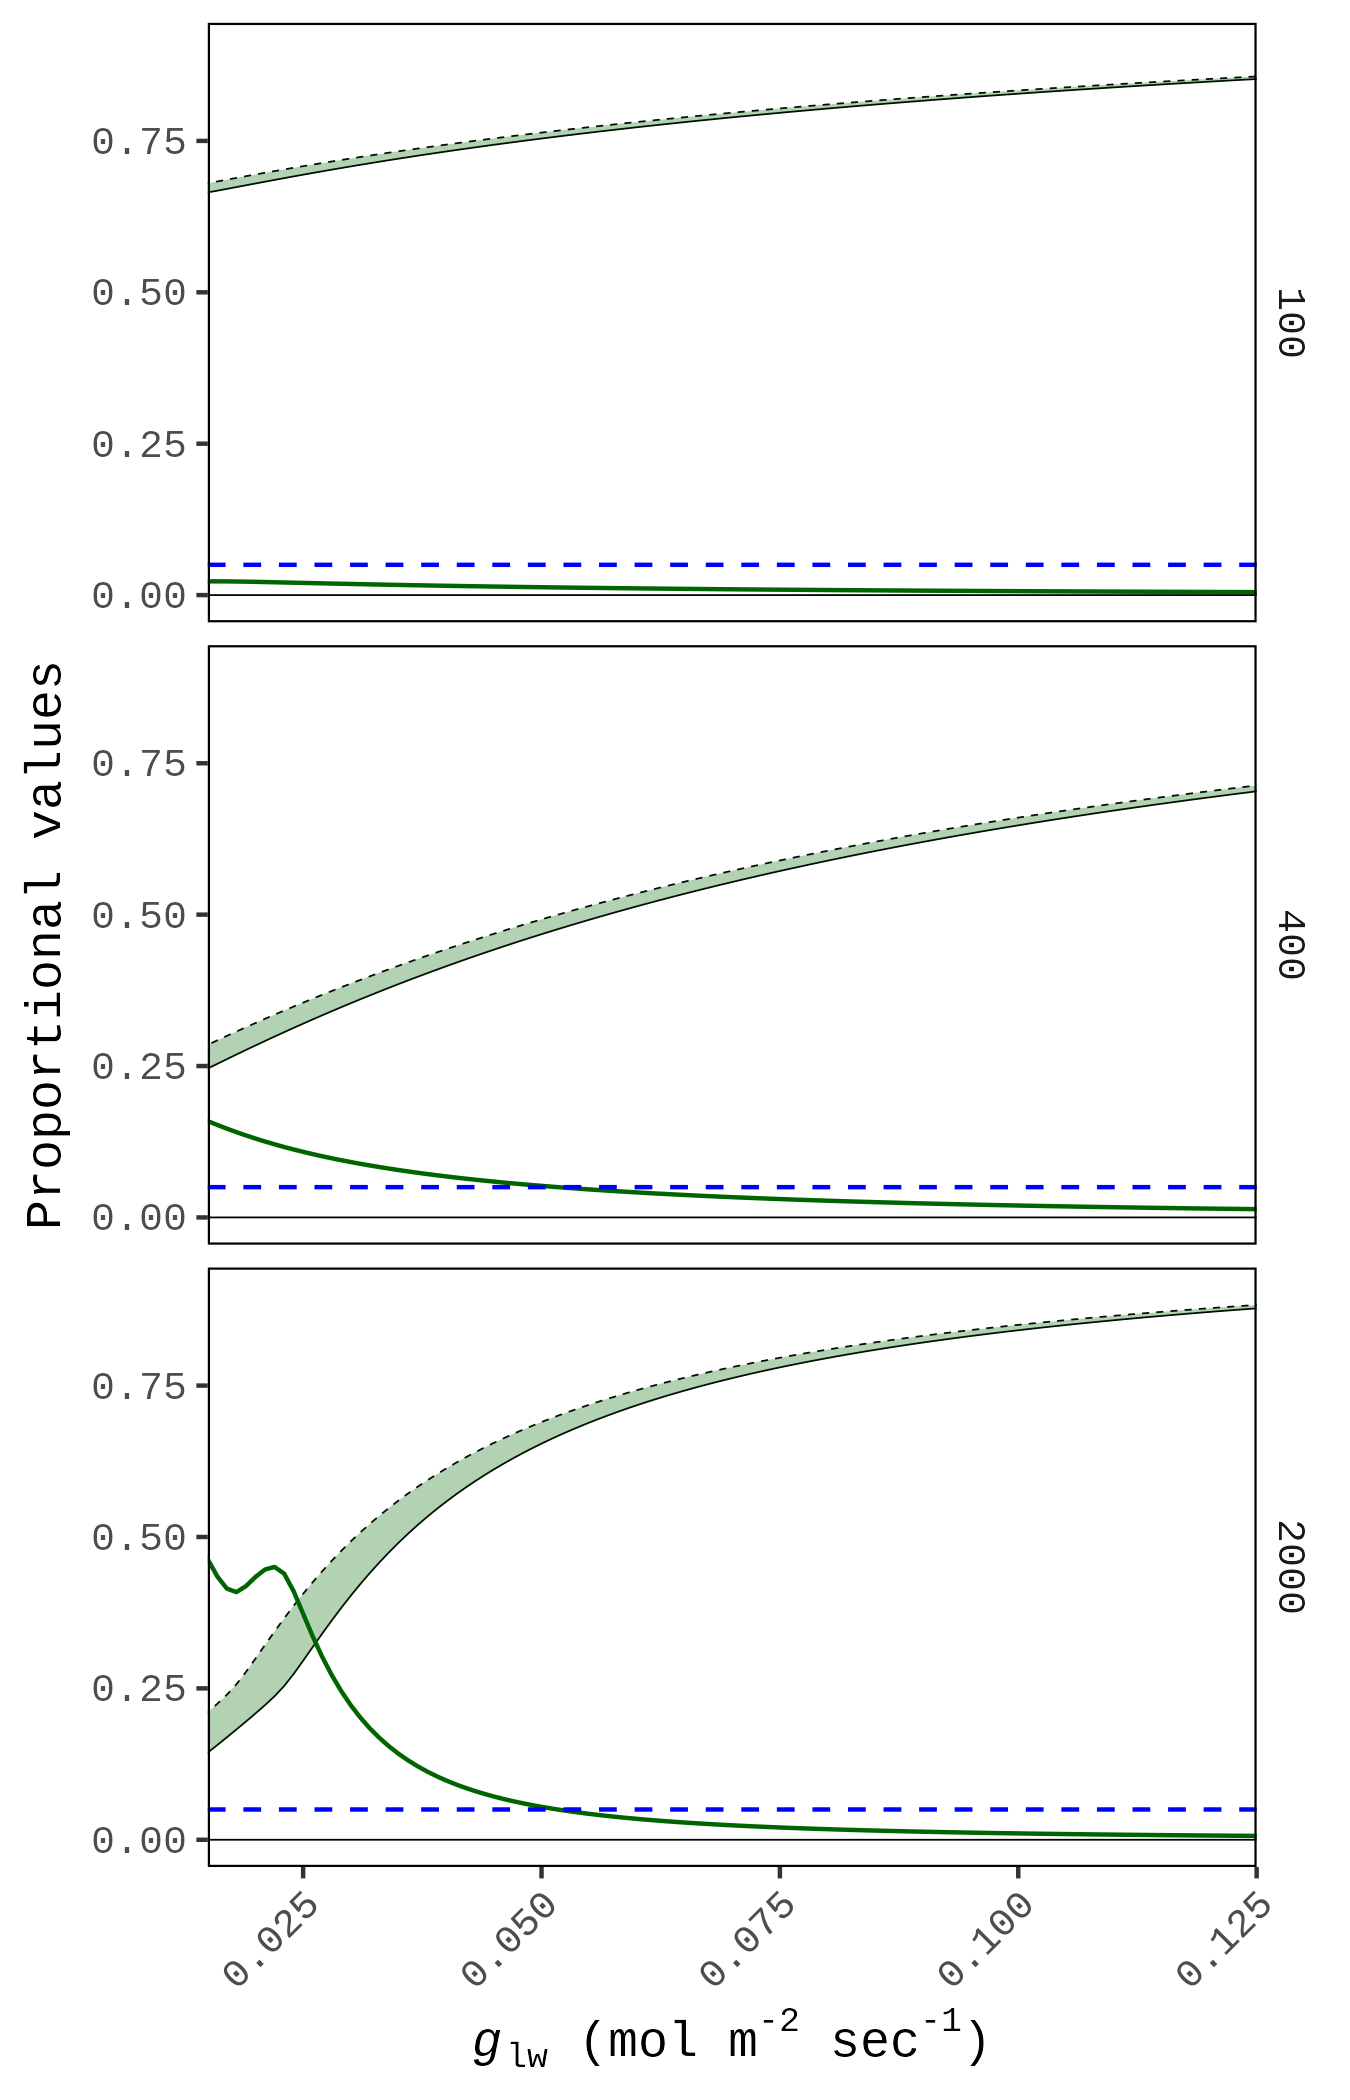

=== Paper Figure 2 (regenerated from author script S3): gcw-corrected Ci with measured species ranges ===


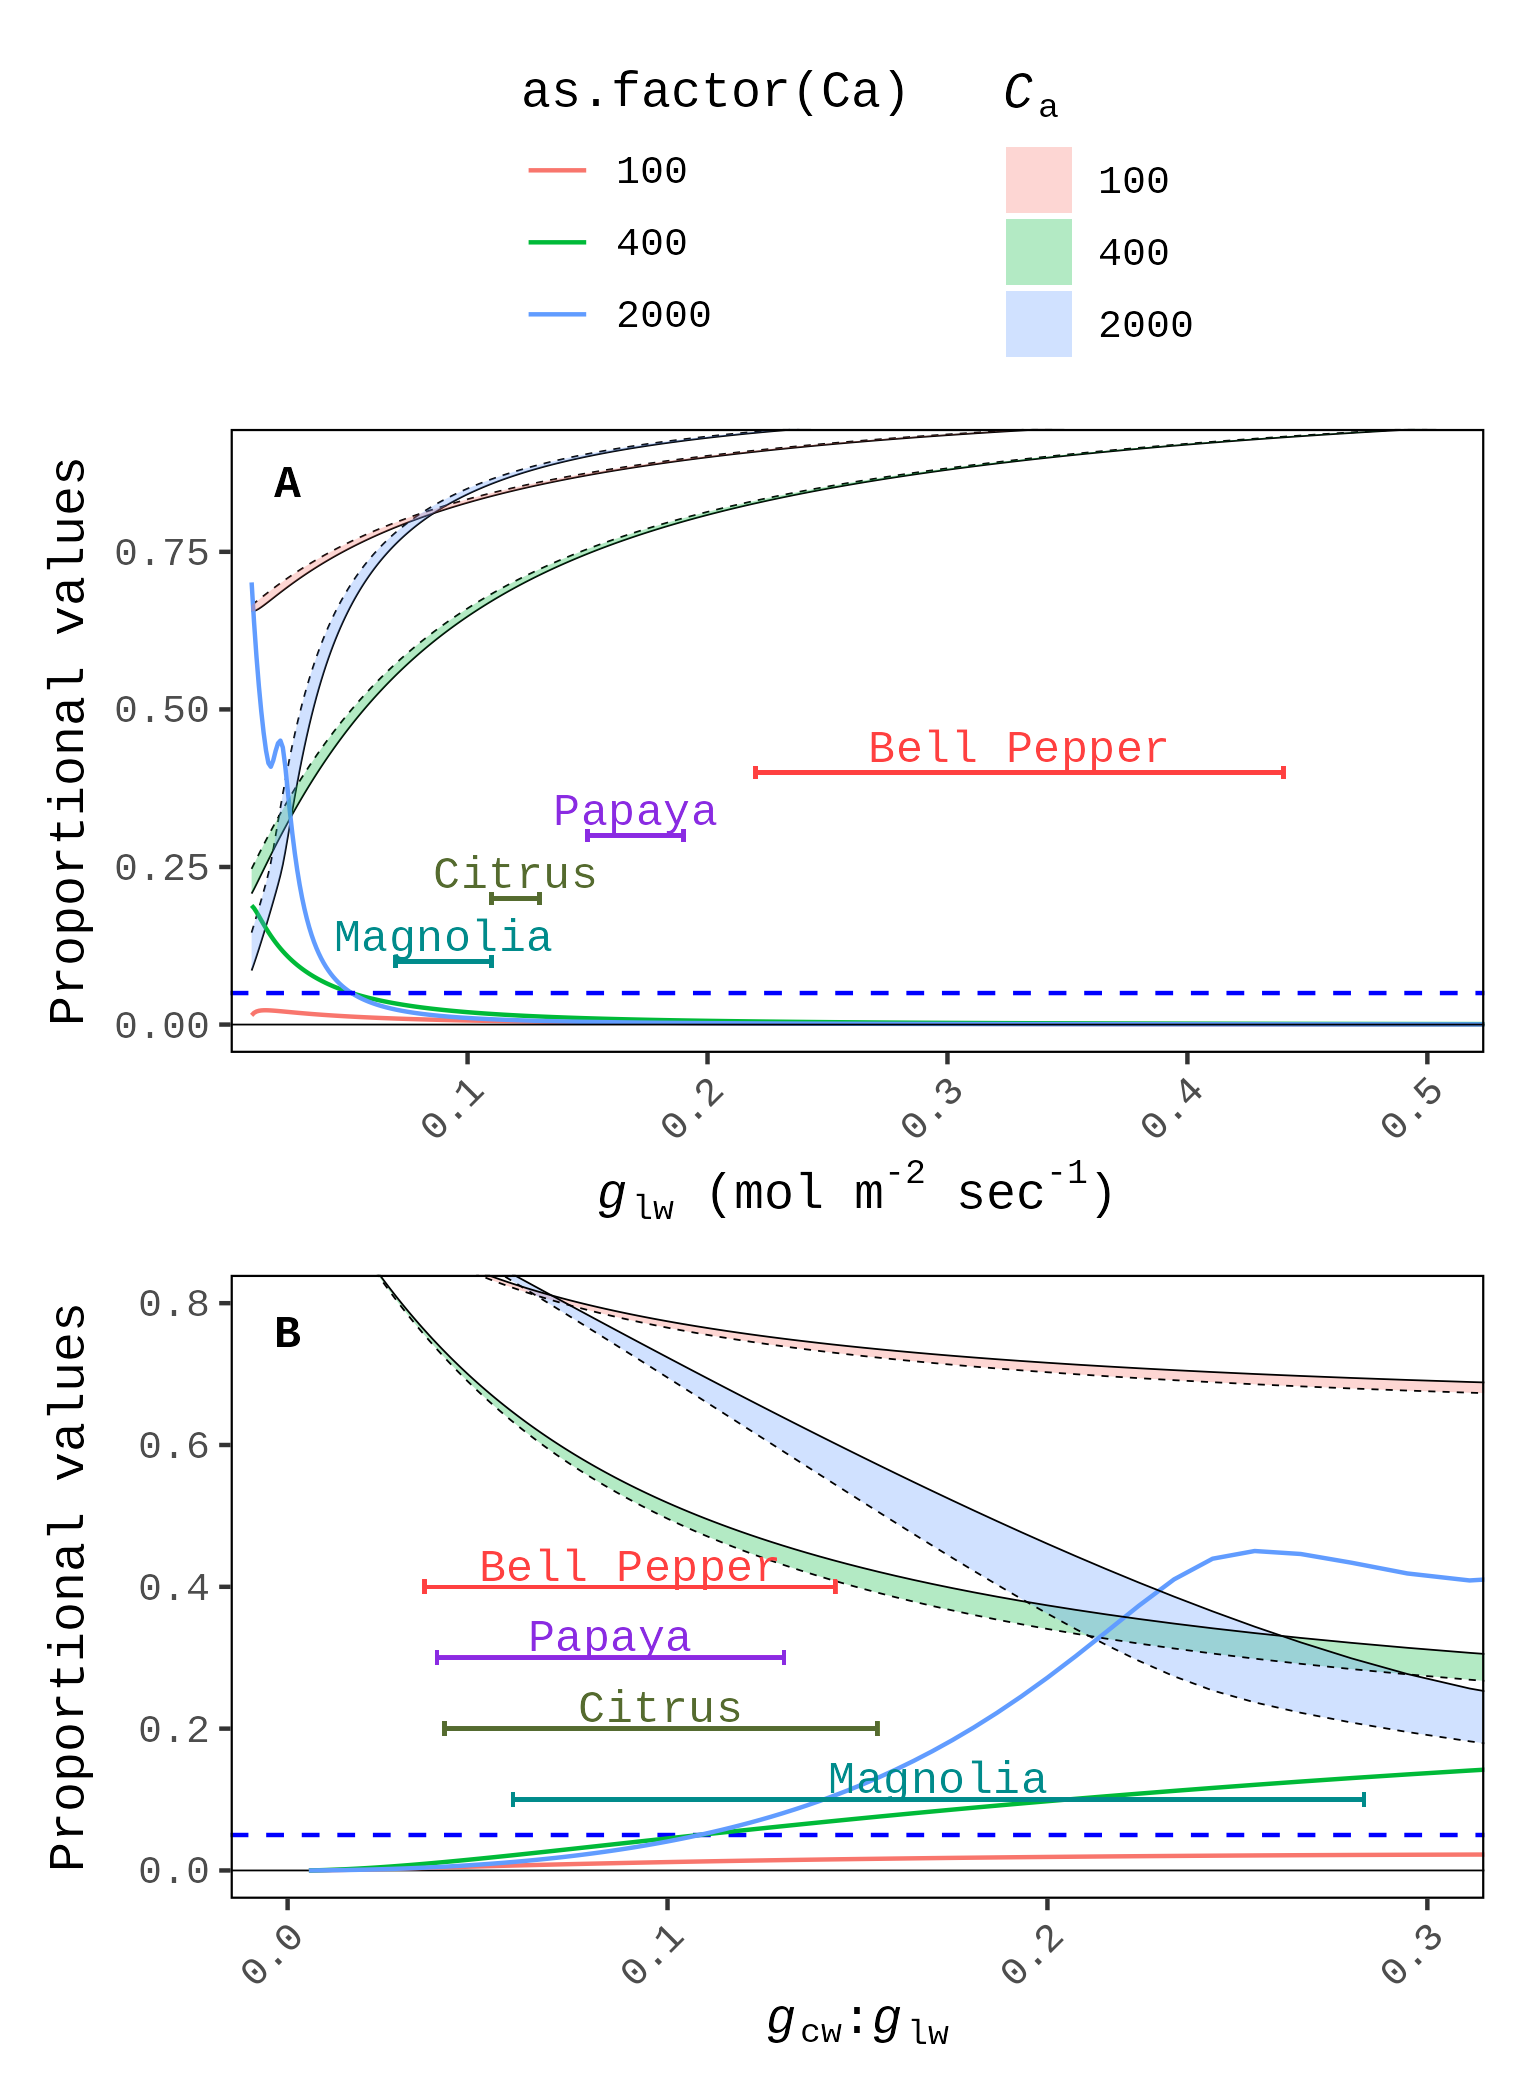

In [ ]:
from IPython.display import Image, display

FIG1 = "/content/phenopaper_out/Figure 1 overall model Duursma.png"
FIG2 = "/content/phenopaper_out/Figure 2 gcw corrected Ci Duursma.png"
for label, path in [
        ("Paper Figure 1 (regenerated from author script S3): proportional Ci vs gtw, by Ca", FIG1),
        ("Paper Figure 2 (regenerated from author script S3): gcw-corrected Ci with measured species ranges", FIG2)]:
    assert Path(path).exists() and Path(path).stat().st_size > 10000, f"missing {path}"
    print("=== " + label + " ===")
    display(Image(filename=path))

### Inspection table for S3 (notebook-created)

Reads the exported `S3_curve_results.csv` (written by the appended export
line) and selects representative $g_{tw}$ rows at $C_a=400$. This table was
created for this notebook; it is not an author figure.
/ **日本語**: S3 の出力 CSV から $C_a=400$・代表的な $g_{tw}$ の行を抜き
出して表示します(未補正と補正後の比、誤差)。表はこのノートブックで追加
作成したものです。

In [ ]:
import pandas as pd

df_s3 = pd.read_csv("/content/phenopaper_out/S3_curve_results.csv")
sel = (df_s3[df_s3["Ca"] == 400]
       .loc[lambda d: d["GS"].isin([0.01, 0.02, 0.05, 0.10, 0.30, 1.00]),
            ["GS", "prop_Ci", "prop_new_Ci", "prop_err"]]
       .reset_index(drop=True))
sel.columns = ["g_tw (mol m-2 s-1)", "proportional Ci, uncorrected",
               "proportional Ci, gcw-corrected", "proportional error"]
display(sel.round(4))

,g_tw (mol m-2 s-1),"proportional Ci, uncorrected","proportional Ci, gcw-corrected",proportional error
0,0.01,0.2471,0.2078,0.1890
1,0.02,0.3210,0.2840,0.1303
2,0.05,0.4921,0.4677,0.0521
3,0.10,0.6602,0.6475,0.0196
4,0.30,0.8825,0.8801,0.0027
5,1.00,1.0000,1.0000,0.0000


## 9. Run S2 — the instrumental-noise simulation (paper Figure 3)

S2 additionally perturbs the sweep by the measured noise bound
$g_{tw} \pm 0.00415$ mol m⁻² s⁻¹, with and without the $g_{cw}$
correction, and plots the resulting $C_i$ uncertainty bands (red = uncorrected
uncertainty, blue = corrected, purple = combined worst-case error) for
$C_a = 400$ (paper Figure 3). / **日本語**: S2 を実行し、測定ノイズ
$g_{tw} \pm 0.00415$ を加えた場合の $C_i$ の不確かさ帯(論文 Figure 3)を
`/content/phenopaper_out/` に保存します。

In [ ]:
run_r_script("/content/S2_repaired.r")
print("S2 done. Saved figures:",
      sorted(p.name for p in Path("/content/phenopaper_out").glob("*.png")))

[    2.0s] ── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──


[    2.0s] ✔ dplyr     1.2.1     ✔ readr     2.2.0


[    2.0s] ✔ forcats   1.0.1     ✔ stringr   1.6.0


[    2.0s] ✔ ggplot2   4.0.3     ✔ tibble    3.3.1


[    2.0s] ✔ lubridate 1.9.5     ✔ tidyr     1.3.2


...

[    2.1s] ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


[   35.4s] Warning message:


[   35.4s] Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.


[   35.4s] ℹ Please use `linewidth` instead. 


[   37.5s] exit code: 0
S2 done. Saved figures: ['Figure 1 overall model Duursma.png', 'Figure 2 gcw corrected Ci Duursma.png', 'Figure 3 machine noise Duursma model.png']


### Results of S2 — paper Figure 3 and inspection table

The PNG is the authors' Figure 3 regenerated here; the table shows the
$C_i$ band half-widths and worst-case error at representative $g_{tw}$
(notebook-created, from the appended export line).
/ **日本語**: S2 が保存した Figure 3 の PNG と、$C_a=400$ の抜き出し表
(このノートブックで追加した CSV 出力から作成)を表示します。

=== Paper Figure 3 (regenerated from author script S2): Ci uncertainty from gcw and machine noise ===


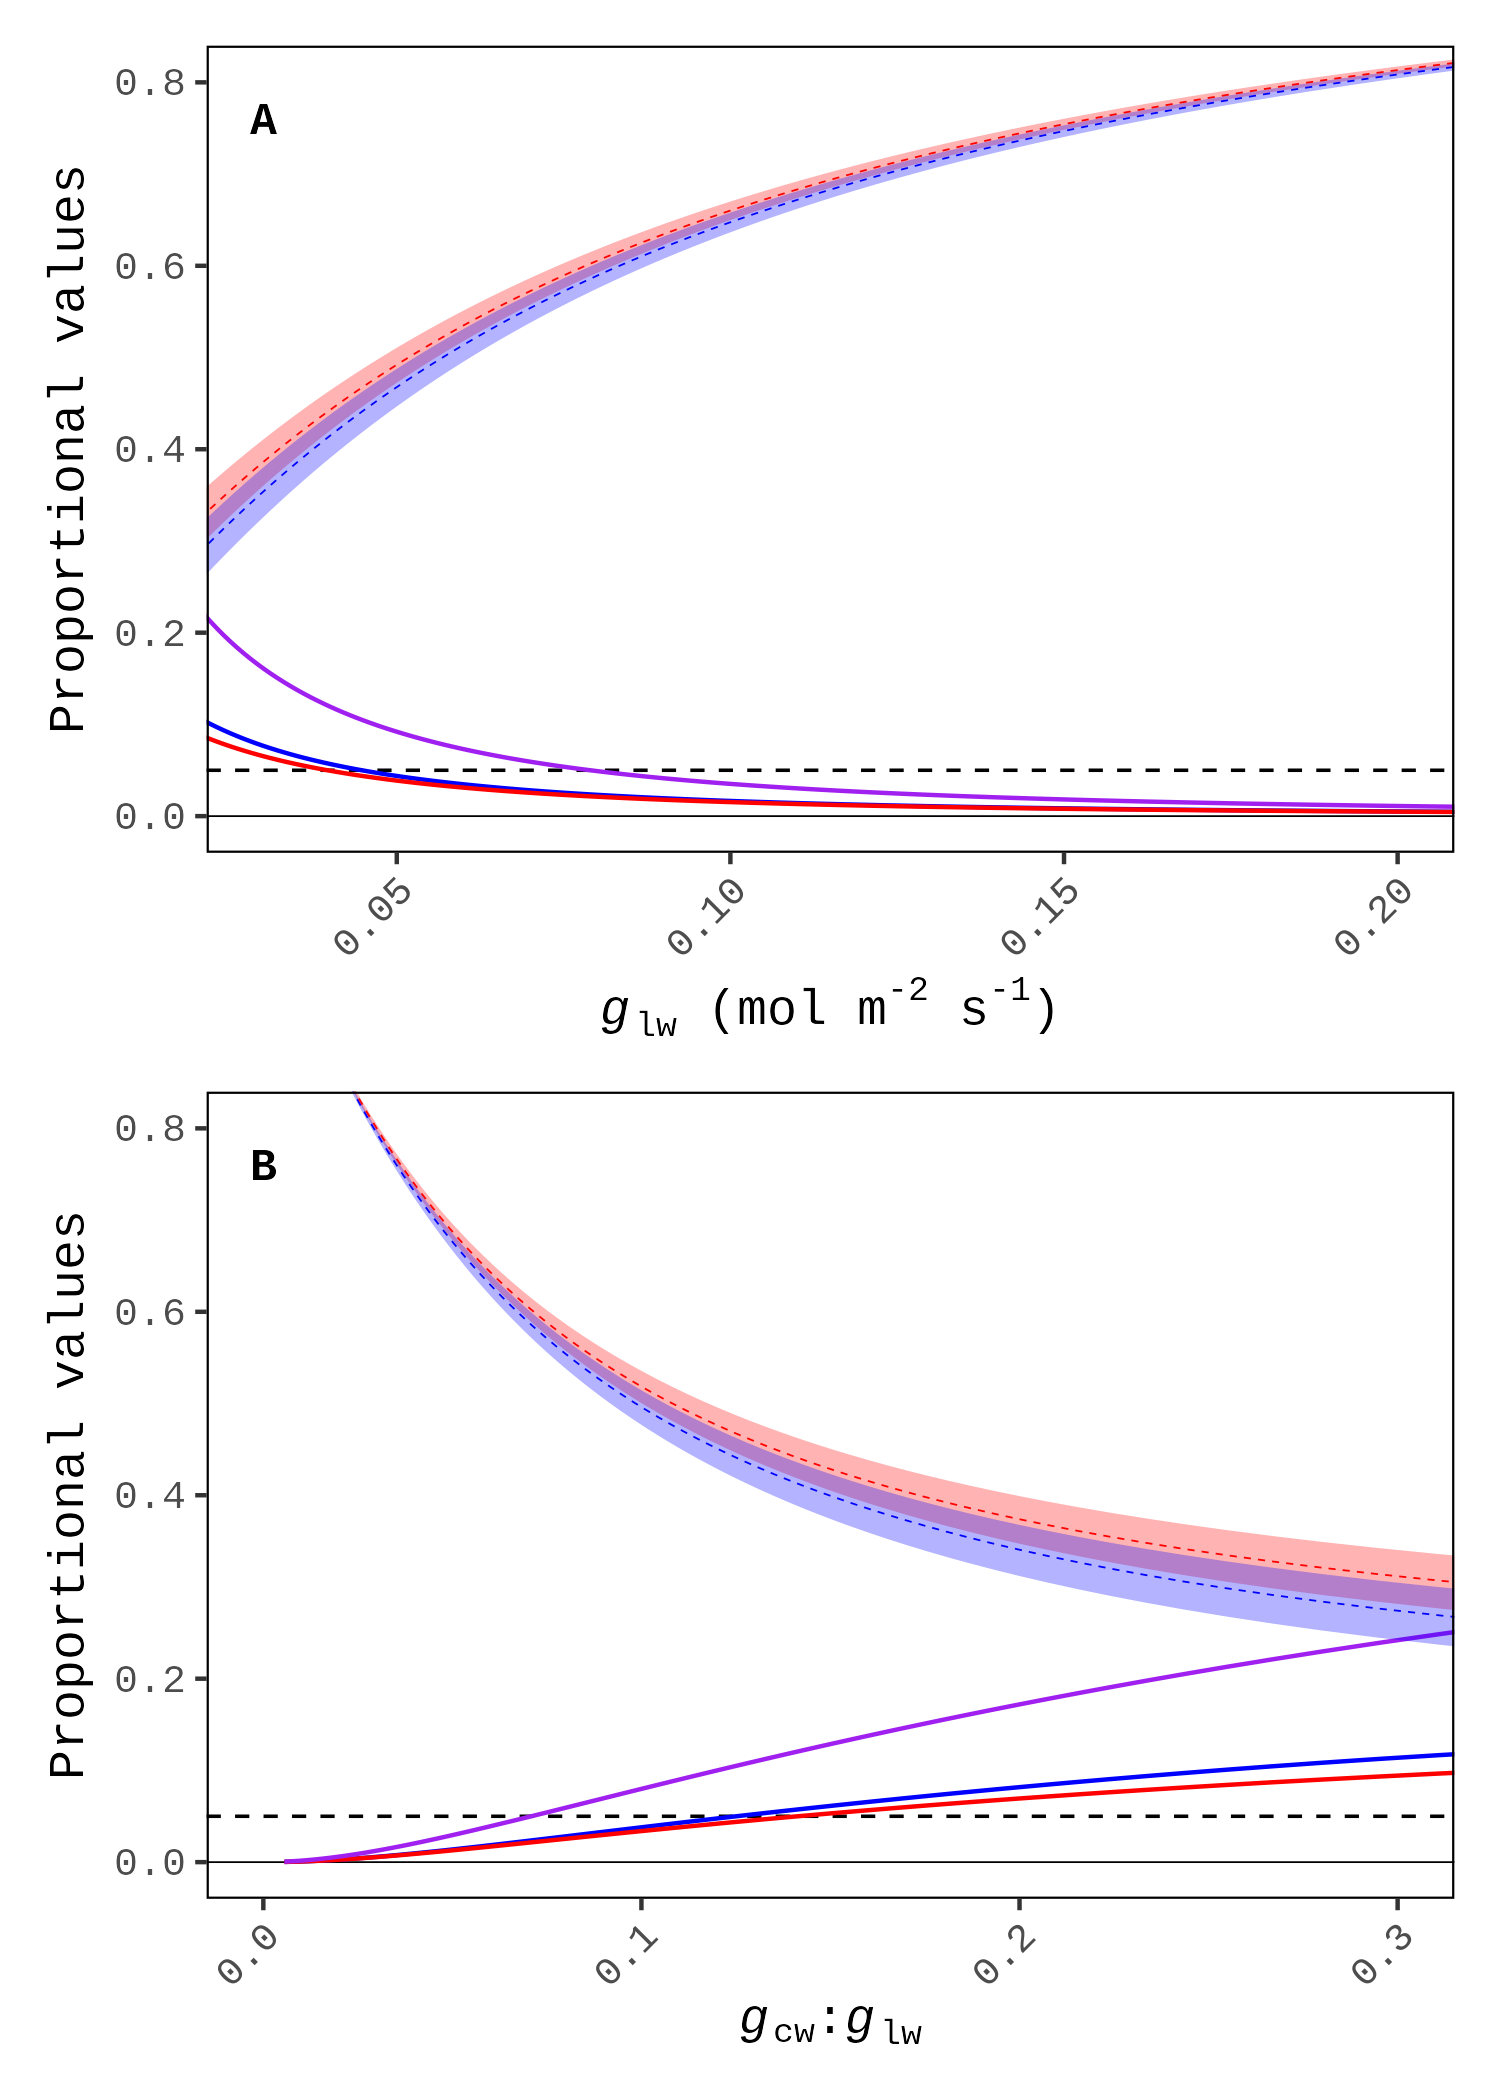

,g_tw (mol m-2 s-1),"half-width of Ci band, uncorrected","half-width of Ci band, gcw-corrected",worst-case proportional error
0,0.01,0.1289,0.0336,0.3418
1,0.02,0.0900,0.1083,0.2296
2,0.05,0.0387,0.0438,0.0920
3,0.10,0.0153,0.0166,0.0352
4,0.30,0.0023,0.0024,0.0053
5,1.00,0.0002,0.0002,0.0005


In [ ]:
FIG3 = "/content/phenopaper_out/Figure 3 machine noise Duursma model.png"
assert Path(FIG3).exists() and Path(FIG3).stat().st_size > 10000, "missing " + FIG3
print("=== Paper Figure 3 (regenerated from author script S2): Ci uncertainty from gcw and machine noise ===")
display(Image(filename=FIG3))

df_s2 = pd.read_csv("/content/phenopaper_out/S2_curve_results.csv")
sel2 = (df_s2[df_s2["Ca"] == 400]
        .loc[lambda d: d["GS"].isin([0.01, 0.02, 0.05, 0.10, 0.30, 1.00]),
             ["GS", "prop_uncertain_old_Ci", "prop_uncertain_Ci", "max_err"]]
        .reset_index(drop=True))
sel2.columns = ["g_tw (mol m-2 s-1)", "half-width of Ci band, uncorrected",
                "half-width of Ci band, gcw-corrected", "worst-case proportional error"]
display(sel2.round(4))

## 10. Interpretation, limitations, and validation record

**What was executed.** The authors' own pinned simulation scripts S3 and S2
(sha256-verified publisher copies) were run end-to-end on the Colab **CPU**
runtime and regenerated paper Figures 1–3 plus two inspection tables.
Consistent with the paper: ignoring $g_{cw}$ biases proportional $C_i$
strongly as $g_{tw}$ falls below ~0.1 mol m⁻² s⁻¹, and this bias is much
larger than the instrumental-noise band (red vs blue in Figure 3).

**Limitations.**
- This is the **simulation branch only**: the curve-fitting branch (S1) needs
  the authors' private Dropbox LI-6800 CSVs and is not reproducible from
  public materials; the Statistix 8.1 ANOVA/t-tests have no script.
- Four documented repairs (§5) were required; the author scripts were
  otherwise used verbatim (digest-checked).
- A single-example run validates the *method demonstration*, not the paper's
  full dataset-level conclusions.
- ggplot2 ≥ 3.4 emits `size=` deprecation warnings from the author's original
  code; plots are unaffected. / **日本語**: 本ノートブックはシミュレーション
  分岐のみを実行しました。S1(私有データ必須)と Statistix の統計検定は対象外。
  修正は 4 箇所のみで、それ以外は著者スクリプトをそのまま使用しています。

**References.** [Accurate photosynthetic parameter estimation at low stomatal conductance: effects of cuticular conductance and instrumental noise](https://doi.org/10.1007/s11120-024-01092-8), *Photosynthesis Research* 160(2-3):111-124 (2024), CC BY 4.0, PMCID PMC11108943.
- Author S2: `11120_2024_1092_MOESM2_ESM.r` (publisher static content, verified 2026-10-27).
- Author S3: `11120_2024_1092_MOESM3_ESM.r` (same source).
- `plantecophys`: Duursma (2015), CRAN; figures composed with ggplot2/patchwork.

## License and attribution note

The article is open access under **CC BY 4.0** via PMC (PMCID PMC11108943),
which permits redistribution with attribution. The supplementary R scripts
carry no explicit license file; they are reproduced here **with attribution
and provenance** for scholarly reuse under the article's CC BY 4.0 terms, and
any reuse beyond that should verify the terms. / **日本語**: 論文本文は
CC BY 4.0 で公開されています。補足 R スクリプトに明示的なライセンス表記は
ないため、出典を明示した形で学術目的に限定して再掲しています。